# 03 · Estimator comparison: convergence and bump size

Experiments B and C.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from mc_greeks import *
from mc_greeks.estimators import exact_estimator_moments, per_path_function
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "results" / "tables"
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

In [2]:
s = pd.read_csv(TABLES / 'B_convergence_summary.csv')
s[(s.n == 50000) & (s.greek != 'price')][['payoff','greek','method','h','bias','sd','rmse','rel_rmse','coverage','runtime']]

,payoff,greek,method,h,bias,sd,rmse,rel_rmse,coverage,runtime
93,interval,delta,Malliavin,NaN,-1.16319e-06,1.64779e-05,1.64777e-05,0.0123442,0.96,0.000738464
94,interval,delta,FD-CRN-fwd,2,-0.000386187,0.000565397,0.000683532,0.512063,0.87,0.00100992
95,interval,delta,FD-CRN-ctr,5,0.000101466,0.000232776,0.000253395,0.189829,0.93,0.00101034
96,interval,delta,FD-IND-fwd,5,-0.00084037,0.000426729,0.000942024,0.705711,0.545,0.00138076
97,interval,delta,FD-IND-ctr,5,9.75841e-05,0.000223188,0.000243077,0.182099,0.91,0.00137733
98,interval,gamma,Malliavin,NaN,1.15304e-08,3.73948e-06,3.73014e-06,0.00959505,0.935,0.000811748
99,interval,gamma,FD-CRN-fwd,5,0.000123951,9.05439e-05,0.000153366,0.394502,0.765,0.00125608
100,interval,gamma,FD-CRN-ctr,10,1.75962e-05,4.15667e-05,4.50419e-05,0.115861,0.94,0.00126169
101,interval,gamma,FD-IND-fwd,5,0.000126872,0.000155691,0.000200536,0.51584,0.875,0.00202006
102,interval,gamma,FD-IND-ctr,10,1.49631e-05,3.68856e-05,3.97195e-05,0.10217,0.935,0.00199756


In [3]:
pd.read_csv(TABLES / 'B_convergence_slopes.csv')[['payoff','greek','method','slope','slope_lo','slope_hi','slope_theory_on_grid']]

,payoff,greek,method,slope,slope_lo,slope_hi,slope_theory_on_grid
0,call,delta,FD-CRN-ctr,-0.477176,-0.503962,-0.450389,-0.5
1,call,delta,FD-CRN-fwd,-0.476469,-0.502408,-0.45053,-0.499628
2,call,delta,FD-IND-ctr,-0.474444,-0.506418,-0.44247,-0.47946
3,call,delta,FD-IND-fwd,-0.239298,-0.295339,-0.183257,-0.255762
4,call,delta,Malliavin,-0.497326,-0.514152,-0.480499,-0.5
5,call,delta,Malliavin-loc,-0.476953,-0.498122,-0.455784,-0.5
6,call,delta,Pathwise,-0.477011,-0.503843,-0.45018,-0.5
7,call,gamma,FD-CRN-ctr,-0.424574,-0.482508,-0.36664,-0.417405
8,call,gamma,FD-CRN-fwd,-0.287087,-0.354859,-0.219316,-0.281451
9,call,gamma,FD-IND-ctr,-0.372086,-0.422793,-0.321378,-0.37856


In [4]:
pd.read_csv(TABLES / 'C_optimal_bumps.csv')

,payoff,greek,method,h_rel_empirical,rmse_empirical,h_rel_theory,rmse_theory_at_opt
0,call,delta,FD-CRN-ctr,0.0001,0.00226426,0.01,0.00240511
1,call,delta,FD-CRN-fwd,0.0001,0.0022771,0.0001,0.00242436
2,call,delta,FD-IND-ctr,0.05,0.0098272,0.05,0.0105886
3,call,delta,FD-IND-fwd,0.05,0.0464019,0.05,0.0444939
4,call,gamma,FD-CRN-ctr,0.1,0.000146102,0.1,0.00014357
5,call,gamma,FD-CRN-fwd,0.01,0.000791857,0.01,0.000796979
6,call,gamma,FD-IND-ctr,0.2,0.000628153,0.2,0.000594921
7,call,gamma,FD-IND-fwd,0.1,0.00687448,0.1,0.00671986
8,call,vega,FD-CRN-ctr,0.0001,0.323681,0.01,0.352424
9,call,vega,FD-CRN-fwd,0.0001,0.323644,0.0001,0.352572


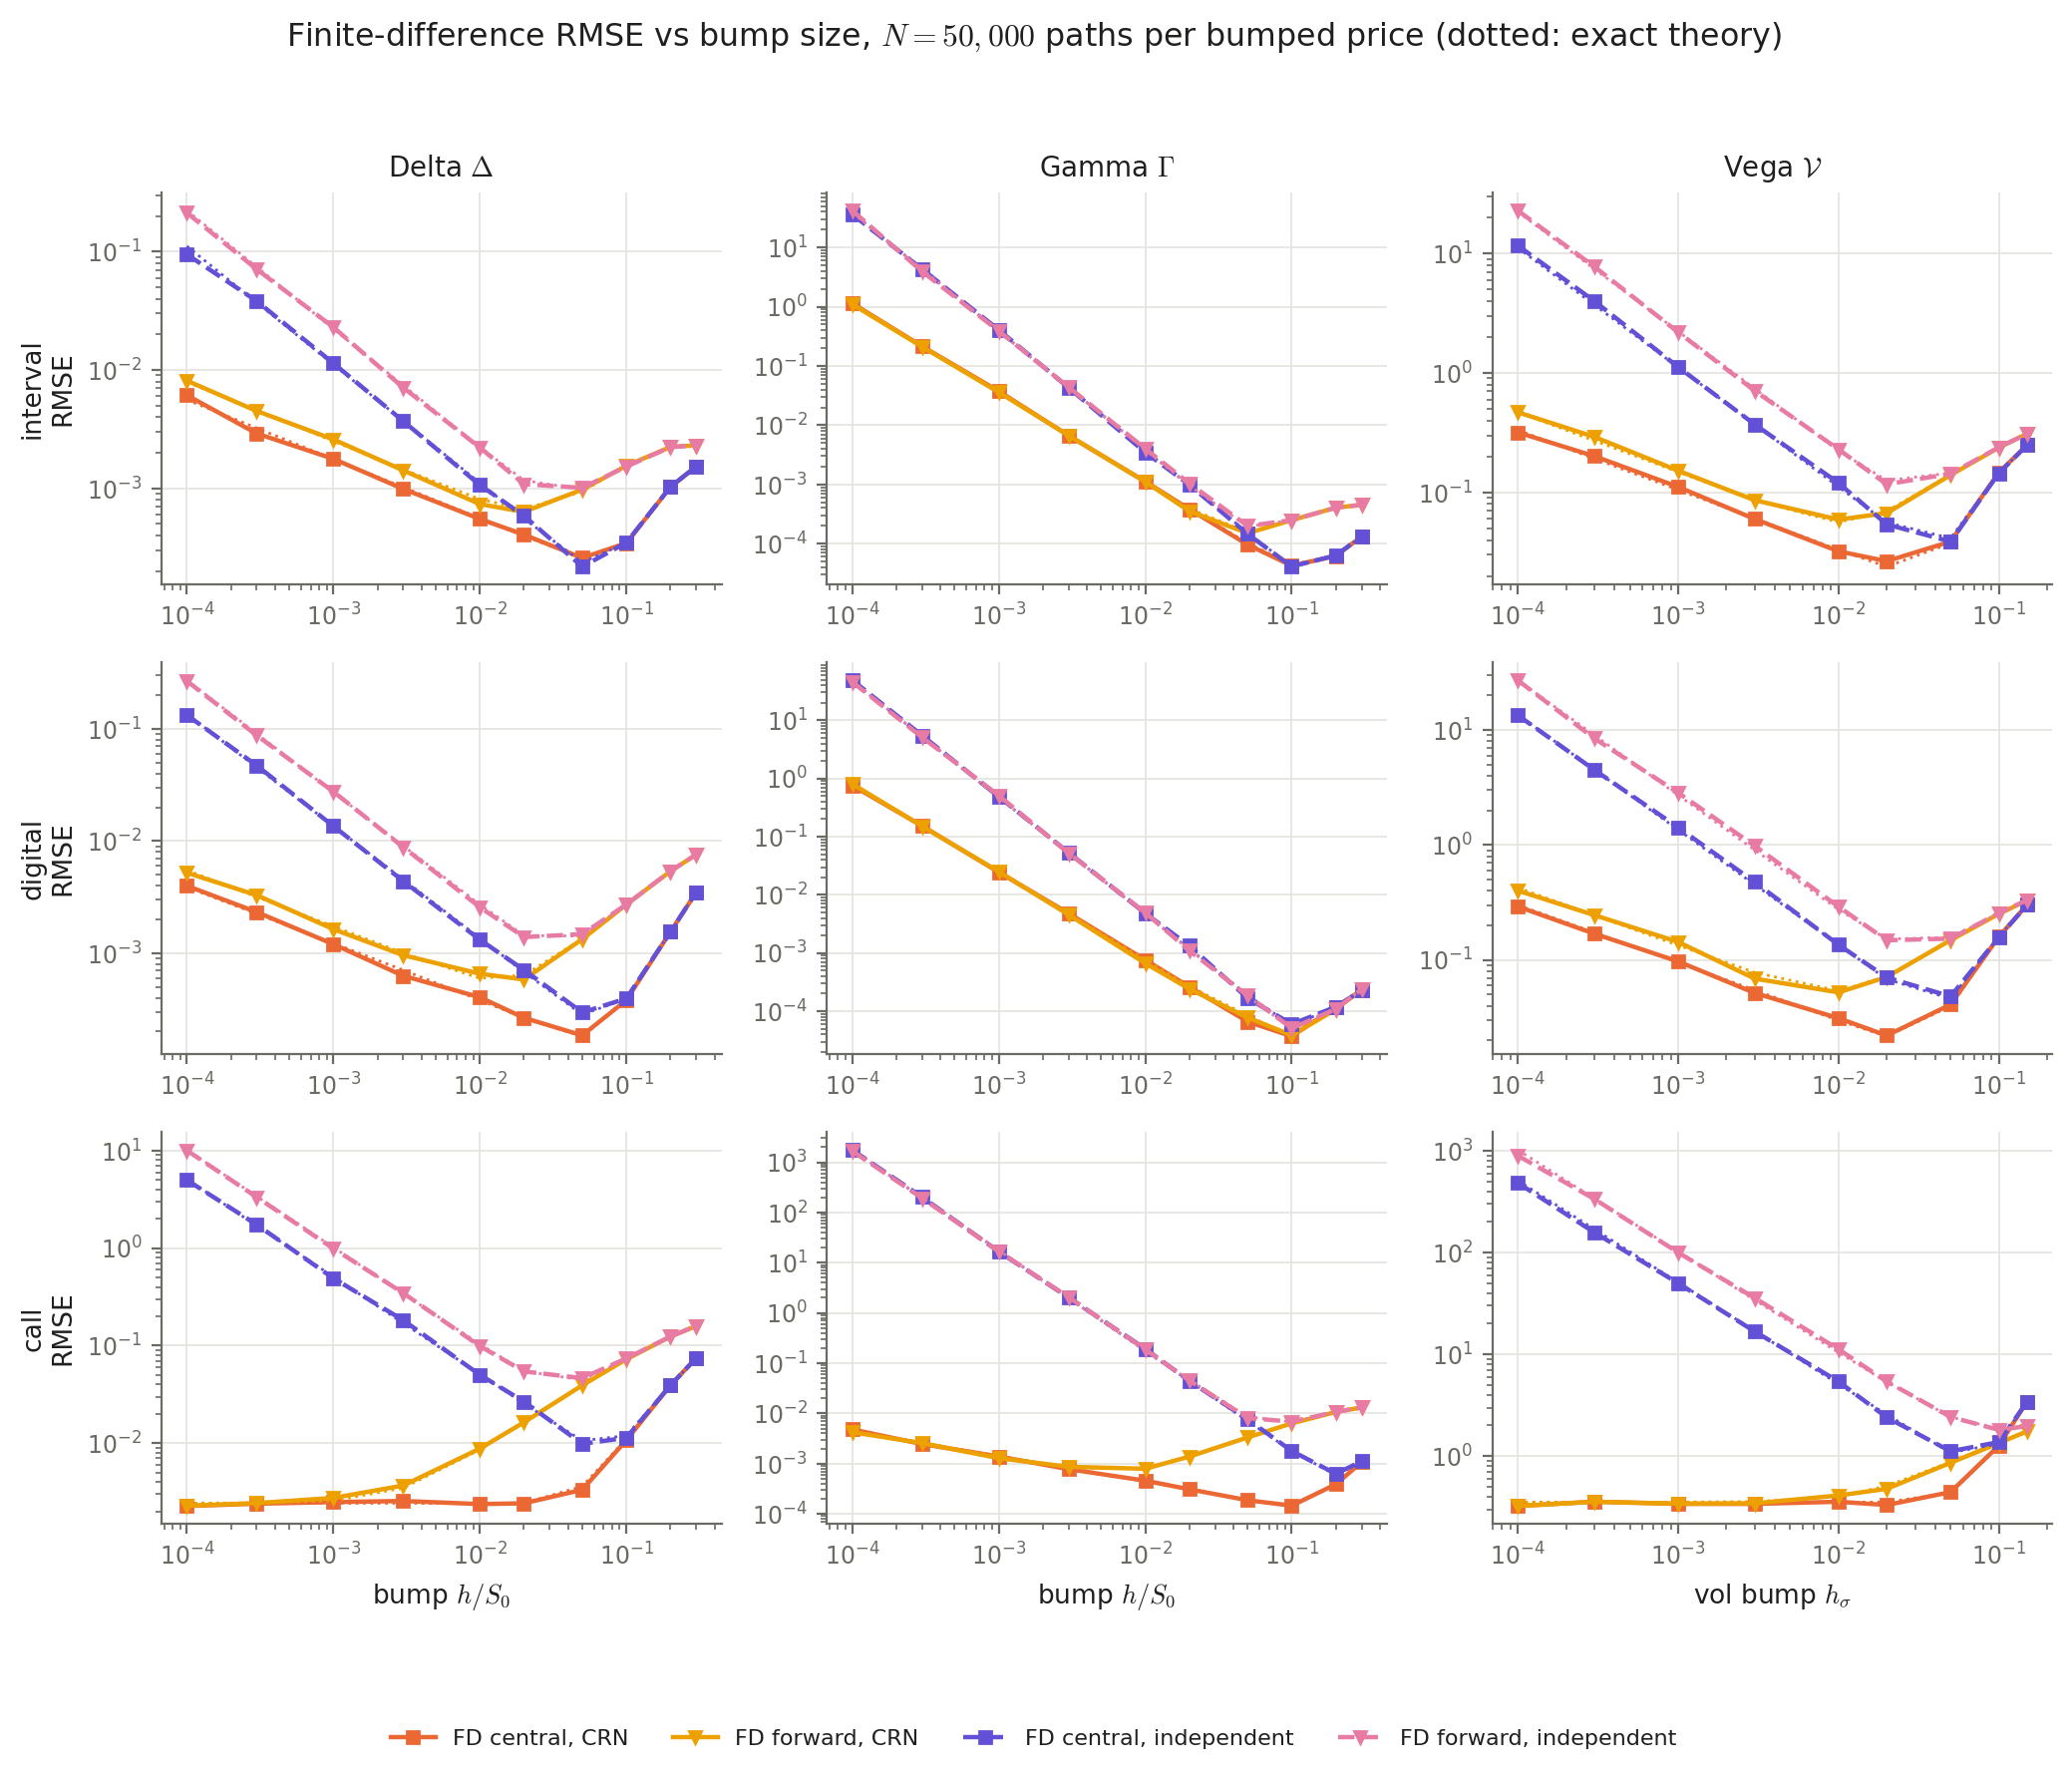

In [5]:
from IPython.display import Image
Image(str(ROOT / 'results/figures/fig06_bump_size_rmse.png'))